# Experiment A — Final dataset-specific preprocessing evaluation

Compare untreated baseline and six active individual techniques on **1000 IAM test lines and all 860 Bentham test lines**, sampled without replacement with seed 5112. One pinned TrOCR checkpoint, fixed decoding and identical ordered test samples within each dataset. No training or combinations. Parts 2 and 3 are unchanged.

Select each technique's parameters separately for IAM and Bentham using only the completed validation summaries: lowest active-configuration CER, then WER; exact ties retain the original prespecified grid order. The setup table records every selection and parameter. IAM: denoising h=7; deskew max_angle=5°, step=0.5° (tied with 10° and 15°); CLAHE clip=1, grid=8x8. Bentham: denoising h=1; deskew max_angle=10°, step=0.25°; CLAHE clip=2, grid=16x16. Both: size height=128, standard grayscale and global min-max intensity normalization.

Baseline remains a separate control even when it outperformed an active technique in validation. This measures the effect of applying each technique; it does not replace unsuccessful techniques with baseline. Frozen configurations and validation provenance are recorded before test inference. The initial shared-parameter run was interrupted after the user clarified dataset-specific selection; its artifacts are retained separately. No parameter was chosen from test scores.

This is final evaluation on fixed test subsets, not the complete partitions. Do not tune from these results. Corpus CER/WER collapse whitespace and retain case/punctuation. Mandatory model RGB conversion, resizing and normalization follow optional preprocessing. Bentham RGBA is composited over white equally for baseline and treatments. Originals remain unchanged. IAM is within TrOCR's training domain; Bentham is historical handwriting. Saved split provenance does not establish absence of overlap with pretrained training data.

SAMPLE_COUNT is a maximum per dataset: select min(SAMPLE_COUNT, test split size) without replacement. No samples are borrowed from train or validation. Actual counts are recorded separately per dataset and shared by baseline and all treatments.

In [2]:
from pathlib import Path
import sys
import json
import platform
import hashlib
import random
from datetime import datetime, timezone
from importlib.metadata import version

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/load_dataset/iam.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset, REVISION, ARCHIVES
from src.models import TrOCRRecognizer
from src.preprocessing import (PreprocessingPipeline, Grayscale, NonLocalMeans,
    Deskew, CLAHE, IntensityNormalization, SizeNormalization)
from src.validation.denoising import adapt_image, evaluate
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
from importlib import import_module
from src.evaluation.selection import select_validation_configuration
SPLIT = "test"
SAMPLE_COUNT = 1000
SEED = 5112
BATCH_SIZE = 8
STUDIES = {
    "denoising": "denoising/20261112T000633091905Z",
    "deskew": "deskew/20261112T002245100371Z",
    "clahe": "clahe/20261112T003254359727Z",
    "grayscale": "grayscale/20261112T004235992760Z",
    "intensity_normalization": "intensity_normalization/20261112T010446875353Z",
    "size_normalization": "size_normalization/20261112T010953112528Z",
}
reference = json.loads((ROOT / "results/validation" / STUDIES["denoising"] / "metadata.json").read_text())
DATASET_REVISION = reference["iam_revision"]
CHECKPOINT = reference["model"]["checkpoint"]
MODEL_REVISION = reference["model"]["revision"]
DEVICE = reference["model"]["device"]
GENERATION = reference["model"]["generation_kwargs"]
pipeline_names = ["baseline", "grayscale", "denoising", "deskew", "clahe", "intensity_normalization", "size_normalization"]
pipelines_by_dataset, selections, selection_rows = {}, {}, []
for dataset_name in ("iam", "bentham"):
    pipelines_by_dataset[dataset_name] = {"baseline": PreprocessingPipeline()}
    selections[dataset_name] = {}
    for technique in pipeline_names[1:]:
        folder = ROOT / "results/validation" / STUDIES[technique]
        scores = pd.read_csv(folder / "comparison.csv", converters={"cer": float, "wer": float})
        chosen = select_validation_configuration(scores, dataset_name)
        registry = import_module("src.validation." + technique).configurations()
        step = registry[chosen["configuration"]]
        validation_metadata = json.loads((folder / "metadata.json").read_text())
        assert validation_metadata["split"] == "validation"
        assert json.loads(json.dumps(step.to_config())) == validation_metadata["configurations"][chosen["configuration"]]
        pipelines_by_dataset[dataset_name][technique] = PreprocessingPipeline((step,))
        selections[dataset_name][technique] = chosen
        selection_rows.append({"dataset": dataset_name, "technique": technique,
            "validation_configuration": chosen["configuration"], "validation_cer": chosen["cer"],
            "validation_wer": chosen["wer"], "parameters": json.dumps(step.to_config())})
assert SPLIT == "test" and SAMPLE_COUNT == 1000 and REVISION == reference["bentham_revision"]
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
frozen_config = {dataset_name: {name: pipe.to_config() for name, pipe in pipes.items()}
                 for dataset_name, pipes in pipelines_by_dataset.items()}
config_digest = hashlib.sha256(json.dumps(frozen_config, sort_keys=True).encode()).hexdigest()
selection_table = pd.DataFrame(selection_rows)
print("Dataset-specific selections: lowest active validation CER, then WER; exact ties retain original grid order.")
display(selection_table)
print("Frozen configuration SHA-256:", config_digest)

Dataset-specific selections: lowest active validation CER, then WER; exact ties retain original grid order.


,dataset,technique,validation_configuration,validation_cer,validation_wer,parameters
0,iam,grayscale,grayscale,0.011541,0.043803,"{""name"": ""grayscale"", ""enabled"": true, ""output..."
1,iam,denoising,nlm_h7,0.010862,0.040598,"{""name"": ""non_local_means"", ""enabled"": true, ""..."
2,iam,deskew,deskew_max5_step0.5,0.011767,0.041667,"{""name"": ""deskew"", ""enabled"": true, ""max_angle..."
3,iam,clahe,clahe_clip1_grid8x8,0.013804,0.045940,"{""name"": ""clahe"", ""enabled"": true, ""clip_limit..."
4,iam,intensity_normalization,intensity_normalization,0.011994,0.045940,"{""name"": ""intensity_normalization"", ""enabled"":..."
5,iam,size_normalization,size_height128,0.011541,0.043803,"{""name"": ""size_normalization"", ""enabled"": true..."
6,bentham,grayscale,grayscale,0.159639,0.295480,"{""name"": ""grayscale"", ""enabled"": true, ""output..."
7,bentham,denoising,nlm_h1,0.154679,0.293275,"{""name"": ""non_local_means"", ""enabled"": true, ""..."
8,bentham,deskew,deskew_max10_step0.25,0.156032,0.299890,"{""name"": ""deskew"", ""enabled"": true, ""max_angle..."
9,bentham,clahe,clahe_clip2_grid16x16,0.146336,0.291069,"{""name"": ""clahe"", ""enabled"": true, ""clip_limit..."


Frozen configuration SHA-256: ed3864f2f81287422af34e216fd234efdc4ba85c88ee3da86d9883830f4c5e6e


In [4]:
datasets = {
    "iam": load_iam_dataset(split=SPLIT, revision=DATASET_REVISION),
    "bentham": load_bentham_dataset(split=SPLIT),
}
sample_counts_by_dataset = {name: min(SAMPLE_COUNT, len(ds)) for name, ds in datasets.items()}
print("Requested maximum per dataset:", SAMPLE_COUNT)
print("Actual test sample counts:", sample_counts_by_dataset)
selected, indices_by_dataset, samples_by_dataset, sample_rows = {}, {}, {}, []
for dataset_name, dataset in datasets.items():
    assert {"image", "text"}.issubset(dataset.column_names)
    count = sample_counts_by_dataset[dataset_name]
    if count == 0:
        raise ValueError(f"{dataset_name} test split is empty.")
    if count < SAMPLE_COUNT:
        print(f"{dataset_name}: using all {count} test lines; fewer than the requested {SAMPLE_COUNT}.")
    indices = sorted(np.random.default_rng(SEED).choice(len(dataset), count, replace=False).tolist())
    indices_by_dataset[dataset_name] = indices
    subset = dataset.select(indices)
    if dataset_name == "iam":
        subset = subset.add_column("id", [f"sample_{i}" for i in indices])
    selected[dataset_name] = subset
    samples = []
    for index, row in zip(indices, subset):
        assert isinstance(row["text"], str) and row["text"].strip()
        image = adapt_image(row["image"])
        sample = {"id": row["id"], "image": image, "ground_truth": row["text"]}
        samples.append(sample)
        sample_rows.append({"dataset": dataset_name, "sample_id": sample["id"],
            "dataset_index": index, "source_mode": row["image"].mode,
            "mode": image.mode, "width": image.width, "height": image.height,
            "ground_truth": row["text"]})
    assert len({s["id"] for s in samples}) == count
    samples_by_dataset[dataset_name] = samples
sample_info = pd.DataFrame(sample_rows)
print("Test split sizes:", {name: len(ds) for name, ds in datasets.items()})
display(sample_info.groupby(["dataset", "source_mode", "mode"]).size().rename("selected_lines").to_frame())
display(sample_info.groupby("dataset").head(2))

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Requested maximum per dataset: 1000
Actual test sample counts: {'iam': 1000, 'bentham': 860}
bentham: using all 860 test lines; fewer than the requested 1000.
Test split sizes: {'iam': 2915, 'bentham': 860}


,,,selected_lines
dataset,source_mode,mode,
bentham,RGBA,RGB,860
iam,L,L,1000


,dataset,sample_id,dataset_index,source_mode,mode,width,height,ground_truth
0,iam,sample_0,0,L,L,2611,128,"assuredness "" Bella Bella Marie "" ( Parlophone..."
1,iam,sample_6,6,L,L,3232,128,He is also a director of a couple of garages ....
1000,bentham,096_028_001_01_01,0,RGBA,RGB,194,87,brain.
1001,bentham,096_028_001_01_02,1,RGBA,RGB,1538,105,"From this review then it appears, that"


## Final inference and saved artifacts

Load TrOCR once and warm up before recording timings. Run each frozen configuration on both fixed test subsets. Save configuration/selection provenance and sample manifests before inference, then checkpoint predictions after every batch. Results are under results/test/experiment_a/<UTC run ID>/<dataset>/<configuration>/.

Timings include mandatory processor transforms and generation; optional preprocessing is separate. Model loading and warm-up are excluded. This sequential run is not a controlled speed benchmark. If interrupted within this kernel, rerun only the inference cell to resume. Do not rerun setup to choose another test sample or alter parameters.

In [5]:
# Resume only when the selected samples and frozen settings match.
existing_metadata = {}
if "run_dir" in globals() and (run_dir / "metadata.json").is_file():
    existing_metadata = json.loads((run_dir / "metadata.json").read_text())
if (existing_metadata.get("frozen_configuration_sha256") != config_digest
        or existing_metadata.get("sample_counts_by_dataset") != sample_counts_by_dataset
        or existing_metadata.get("sample_indices") != indices_by_dataset
        or existing_metadata.get("seed") != SEED
        or existing_metadata.get("split") != SPLIT):
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    run_dir = ROOT / "results/test/experiment_a" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    metadata = {
        "experiment_id": run_id, "phase": "final_test", "split": SPLIT,
        "requested_sample_count_per_dataset": SAMPLE_COUNT,
        "sample_counts_by_dataset": sample_counts_by_dataset, "seed": SEED,
        "sampling": "numpy default_rng seeded without replacement; sorted source indices per dataset",
        "sample_indices": indices_by_dataset, "frozen_configuration_sha256": config_digest,
        "preprocessing": frozen_config, "selection_studies": STUDIES, "validation_selections": selections,
        "selection_rule": "per-dataset lowest active validation CER; WER tie-breaker; exact ties use grid order",
        "datasets": {name: {"split_size": len(ds), "fingerprint": ds._fingerprint,
            "selected_fingerprint": selected[name]._fingerprint,
            "revision": DATASET_REVISION if name == "iam" else REVISION}
            for name, ds in datasets.items()},
        "bentham_archive_sha256": ARCHIVES,
        "normalization": "collapse whitespace; retain case and punctuation",
        "input_adaptation": "RGBA white composite; preserve L/RGB",
        "python": platform.python_version(), "platform": platform.platform(),
        "versions": {p: version(p) for p in ("torch", "transformers", "datasets",
            "huggingface-hub", "jiwer", "numpy", "Pillow", "opencv-python-headless", "pandas", "matplotlib")},
    }
    sample_info.to_csv(run_dir / "samples.csv", index=False)
    selection_table.to_csv(run_dir / "validation_parameter_selections.csv", index=False)
    (run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
    (run_dir / "status.json").write_text(json.dumps({"status": "running", "expected_dataset_configuration_pairs": 14}))
saved_protocol = json.loads((run_dir / "metadata.json").read_text())
metadata = saved_protocol.copy()
assert saved_protocol["frozen_configuration_sha256"] == config_digest
assert saved_protocol["sample_indices"] == indices_by_dataset
assert saved_protocol["split"] == "test" and saved_protocol["sample_counts_by_dataset"] == sample_counts_by_dataset
if ("model" not in globals() or model.revision != MODEL_REVISION or str(model.device) != DEVICE
        or model.checkpoint != CHECKPOINT or model.generation_kwargs != GENERATION):
    model = TrOCRRecognizer(checkpoint=CHECKPOINT, revision=MODEL_REVISION,
                           device=DEVICE, generation_kwargs=GENERATION)
    _ = model.predict(samples_by_dataset["iam"][0]["image"])
metadata["model"] = model.to_config()
(run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
assert config_digest == hashlib.sha256(json.dumps({dataset_name: {name: p.to_config() for name, p in pipes.items()} for dataset_name, pipes in pipelines_by_dataset.items()}, sort_keys=True).encode()).hexdigest()
summaries = []
for name in pipeline_names:
    for dataset_name, dataset in selected.items():
        pipeline = pipelines_by_dataset[dataset_name][name]
        # The historical 250-line checkpoints do not match this 1000-line subset.
        result = evaluate(dataset, dataset_name, model, name, pipeline, run_dir, BATCH_SIZE)
        summaries.append(result)
        pd.DataFrame(summaries).to_csv(run_dir / "partial_summary.csv", index=False)
        print(result, flush=True)
summary = pd.DataFrame(summaries)
assert len(summary) == 14 and summary.sample_count.eq(summary.dataset.map(sample_counts_by_dataset)).all()
for metric in ("cer", "wer"):
    base = summary[summary.configuration == "baseline"].set_index("dataset")[metric]
    summary[f"{metric}_change_pp"] = 100 * (summary[metric] - summary.dataset.map(base))
    summary[f"{metric}_relative_change_pct"] = 100 * (summary[metric] / summary.dataset.map(base) - 1)
summary["total_seconds"] = summary.preprocessing_seconds + summary.inference_seconds
summary["seconds_per_line"] = summary.total_seconds / summary.sample_count
frames = []
for dataset_name in selected:
    for name in pipeline_names:
        frame = pd.read_csv(run_dir / dataset_name / name / "predictions.csv", keep_default_na=False)
        assert frame.sample_id.tolist() == [s["id"] for s in samples_by_dataset[dataset_name]]
        frames.append(frame.assign(dataset=dataset_name, configuration=name))
predictions = pd.concat(frames, ignore_index=True)
summary.to_csv(run_dir / "summary.csv", index=False)
predictions.to_csv(run_dir / "predictions.csv", index=False)
(run_dir / "status.json").write_text(json.dumps({"status": "inference_complete", "completed_dataset_configuration_pairs": 14}))
print("Saved final test results:", run_dir)
display(summary)

W1115 17:49:38.837000 70076 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


iam/baseline: 8/1000
iam/baseline: 80/1000
iam/baseline: 160/1000
iam/baseline: 240/1000
iam/baseline: 320/1000
iam/baseline: 400/1000
iam/baseline: 480/1000
iam/baseline: 560/1000
iam/baseline: 640/1000
iam/baseline: 720/1000
iam/baseline: 800/1000
iam/baseline: 880/1000
iam/baseline: 960/1000
iam/baseline: 1000/1000
{'dataset': 'iam', 'configuration': 'baseline', 'sample_count': 1000, 'cer': 0.04870893385177769, 'wer': 0.11933602512337371, 'preprocessing_seconds': 0.031105328380363062, 'inference_seconds': 284.1662463368848}
bentham/baseline: 8/860
bentham/baseline: 80/860
bentham/baseline: 160/860
bentham/baseline: 240/860
bentham/baseline: 320/860
bentham/baseline: 400/860
bentham/baseline: 480/860
bentham/baseline: 560/860
bentham/baseline: 640/860
bentham/baseline: 720/860
bentham/baseline: 800/860
bentham/baseline: 860/860
{'dataset': 'bentham', 'configuration': 'baseline', 'sample_count': 860, 'cer': 0.1740543351098401, 'wer': 0.4412862474877979, 'preprocessing_seconds': 0.3065

,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_change_pp,cer_relative_change_pct,wer_change_pp,wer_relative_change_pct,total_seconds,seconds_per_line
0,iam,baseline,1000,0.048709,0.119336,0.031105,284.166246,0.000000,0.000000,0.000000,0.000000,284.197352,0.284197
1,bentham,baseline,860,0.174054,0.441286,0.306547,237.875591,0.000000,0.000000,0.000000,0.000000,238.182138,0.276956
2,iam,grayscale,1000,0.048709,0.119336,0.042981,276.816173,0.000000,0.000000,0.000000,0.000000,276.859154,0.276859
3,bentham,grayscale,860,0.174054,0.441286,0.335514,238.070674,0.000000,0.000000,0.000000,0.000000,238.406188,0.277216
4,iam,denoising,1000,0.048546,0.118551,60.188534,276.051661,-0.016298,-0.334608,-0.078511,-0.657895,336.240194,0.336240
5,bentham,denoising,860,0.174080,0.439133,114.097987,249.045602,0.002600,0.014937,-0.215332,-0.487964,363.143589,0.422260
6,iam,deskew,1000,0.049035,0.120682,11.691043,284.803615,0.032597,0.669216,0.134590,1.127820,296.494658,0.296495
7,bentham,deskew,860,0.177616,0.447603,38.369269,245.663070,0.356168,2.046303,0.631639,1.431360,284.032340,0.330270
8,iam,clahe,1000,0.050758,0.123598,0.301312,276.118319,0.204894,4.206501,0.426200,3.571429,276.419631,0.276420
9,bentham,clahe,860,0.158222,0.422481,1.106171,238.667270,-1.583258,-9.096341,-1.880563,-4.261548,239.773441,0.278806


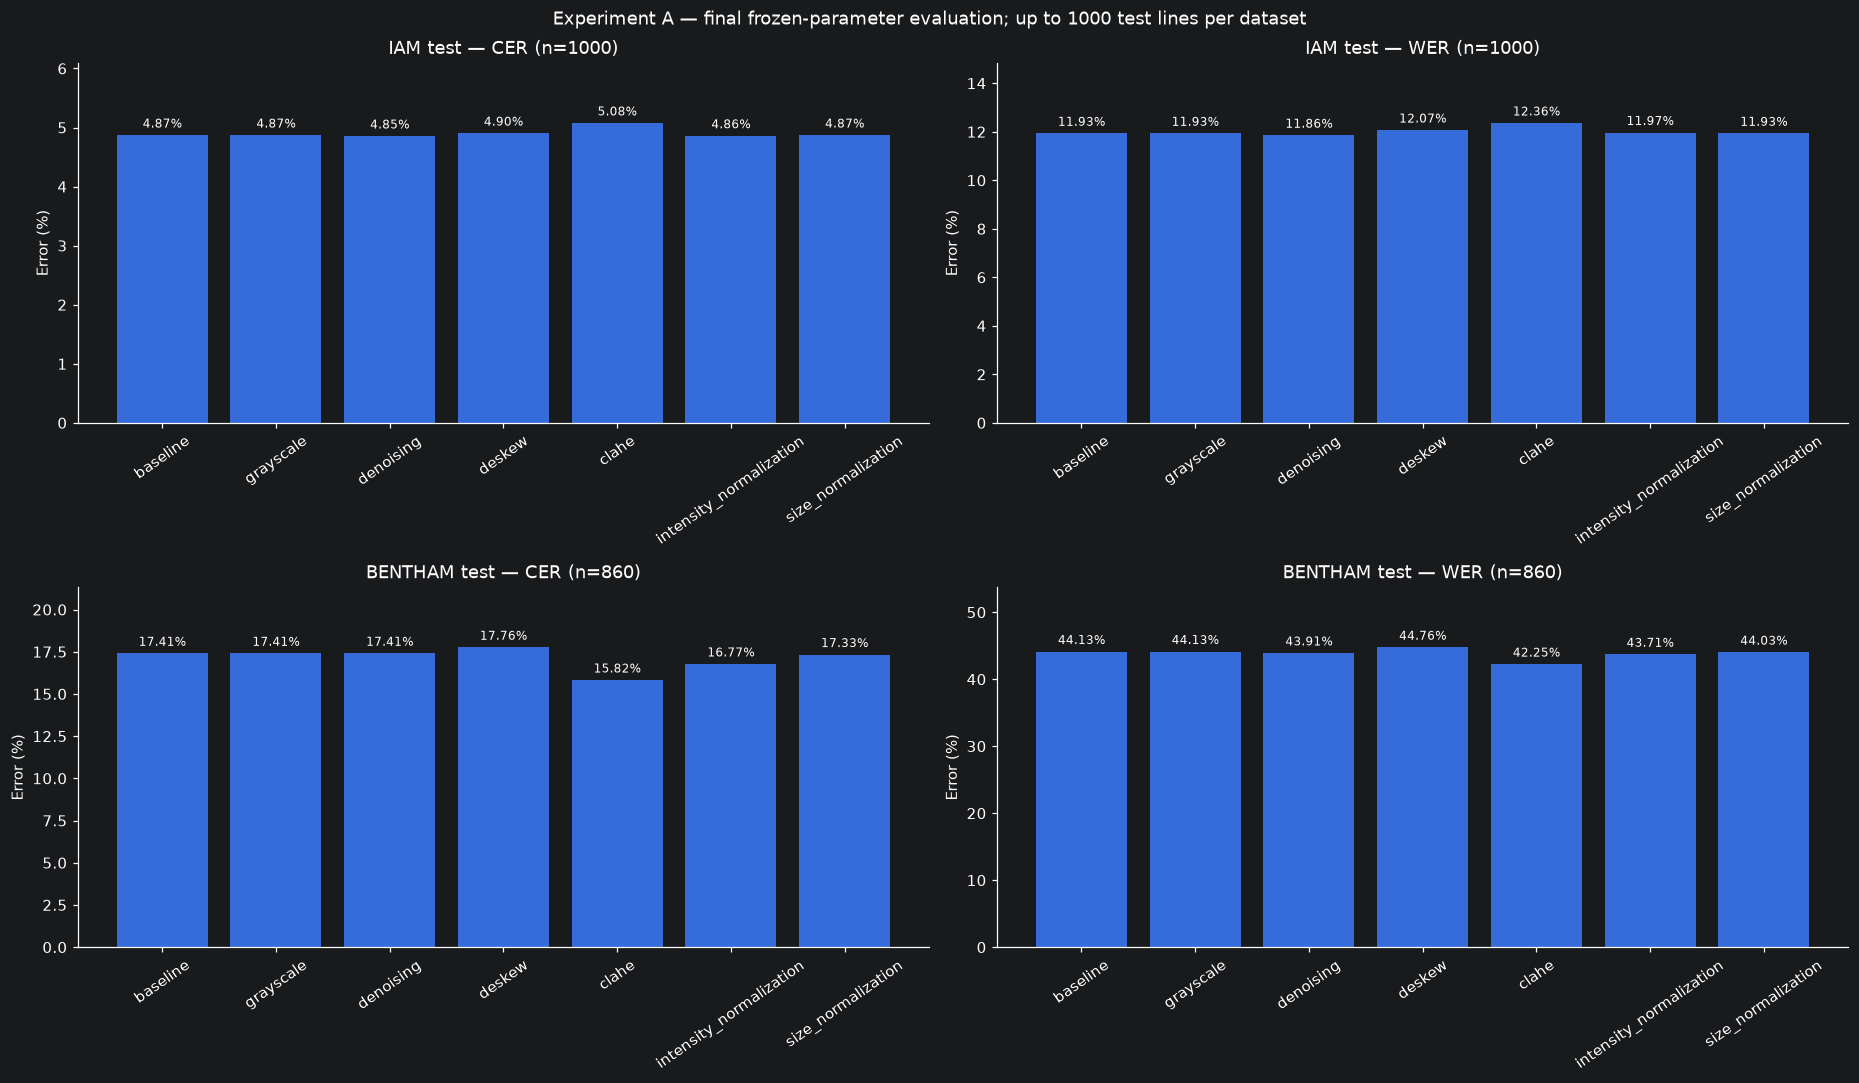

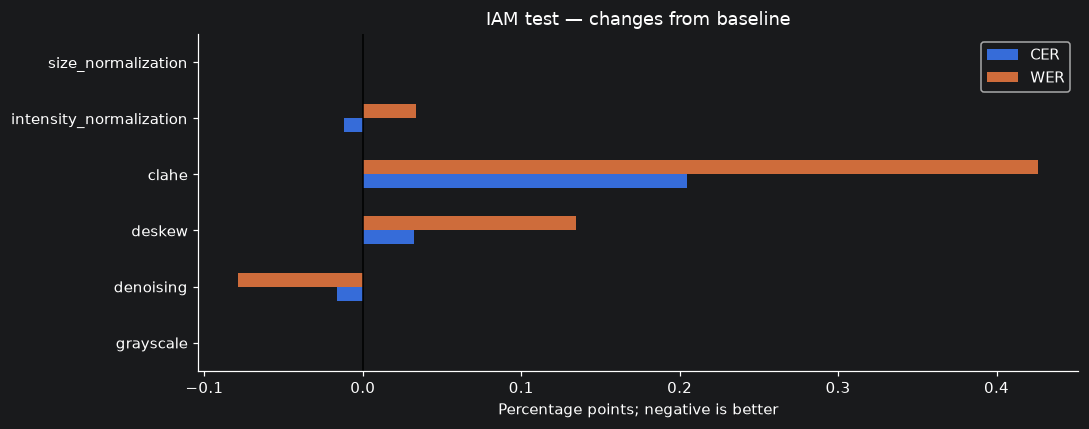

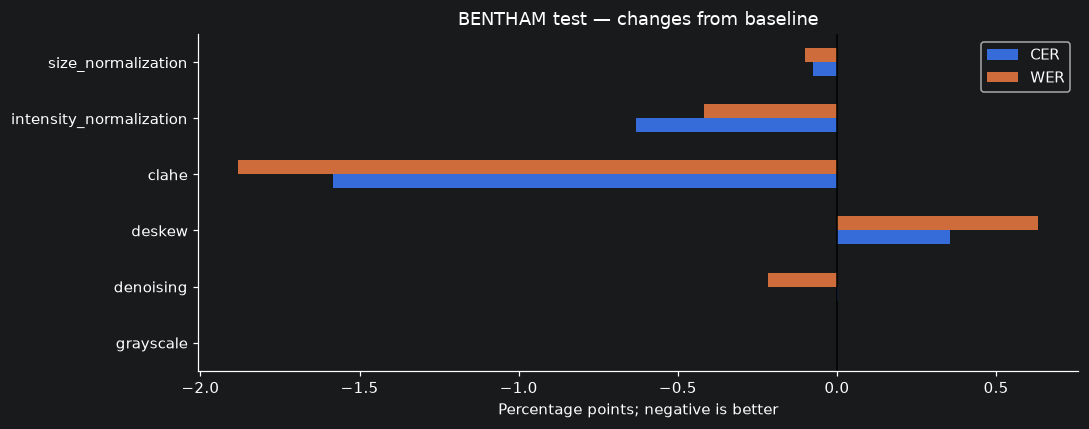

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(17, 10))
for row, dataset_name in enumerate(selected):
    current = summary[summary.dataset == dataset_name].set_index("configuration").loc[pipeline_names]
    for col, metric in enumerate(("cer", "wer")):
        values = 100 * current[metric]
        bars = axes[row, col].bar(current.index, values)
        axes[row, col].bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=3, fontsize=8)
        axes[row, col].set(title=f"{dataset_name.upper()} test — {metric.upper()} (n={sample_counts_by_dataset[dataset_name]})", ylabel="Error (%)")
        axes[row, col].tick_params(axis="x", rotation=35)
        axes[row, col].margins(y=.2)
fig.suptitle("Experiment A — final frozen-parameter evaluation; up to 1000 test lines per dataset")
fig.tight_layout()
fig.savefig(run_dir / "corpus_error_rates.png", bbox_inches="tight")
plt.show()
for dataset_name in selected:
    current = summary[summary.dataset == dataset_name].set_index("configuration").drop(index="baseline")
    ax = current[["cer_change_pp", "wer_change_pp"]].rename(columns={"cer_change_pp":"CER", "wer_change_pp":"WER"}).plot.barh(figsize=(10, 4))
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=f"{dataset_name.upper()} test — changes from baseline", xlabel="Percentage points; negative is better", ylabel="")
    plt.tight_layout()
    plt.savefig(run_dir / f"{dataset_name}_corpus_changes.png", bbox_inches="tight")
    plt.show()

## Where does preprocessing help or hurt?

The next plots pair each line with its own baseline. The scatter diagonal means equal CER. The count chart uses per-line CER to count improved, unchanged, and worsened lines; these counts are diagnostics, not corpus metrics or a statistical significance test. A technique can help many short lines and still worsen corpus CER if it damages longer lines.

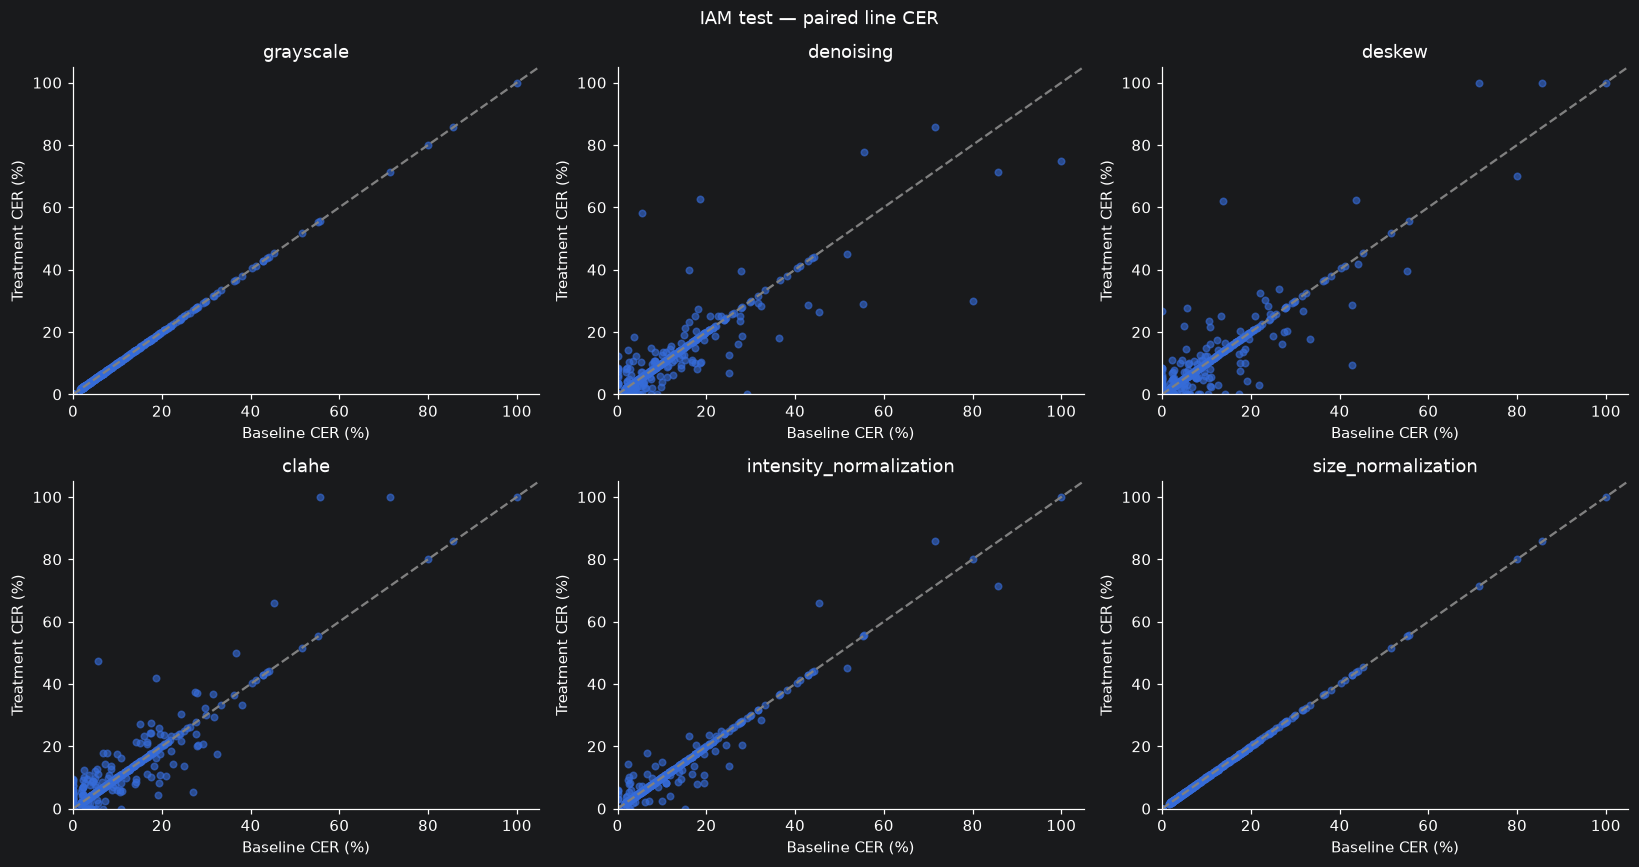

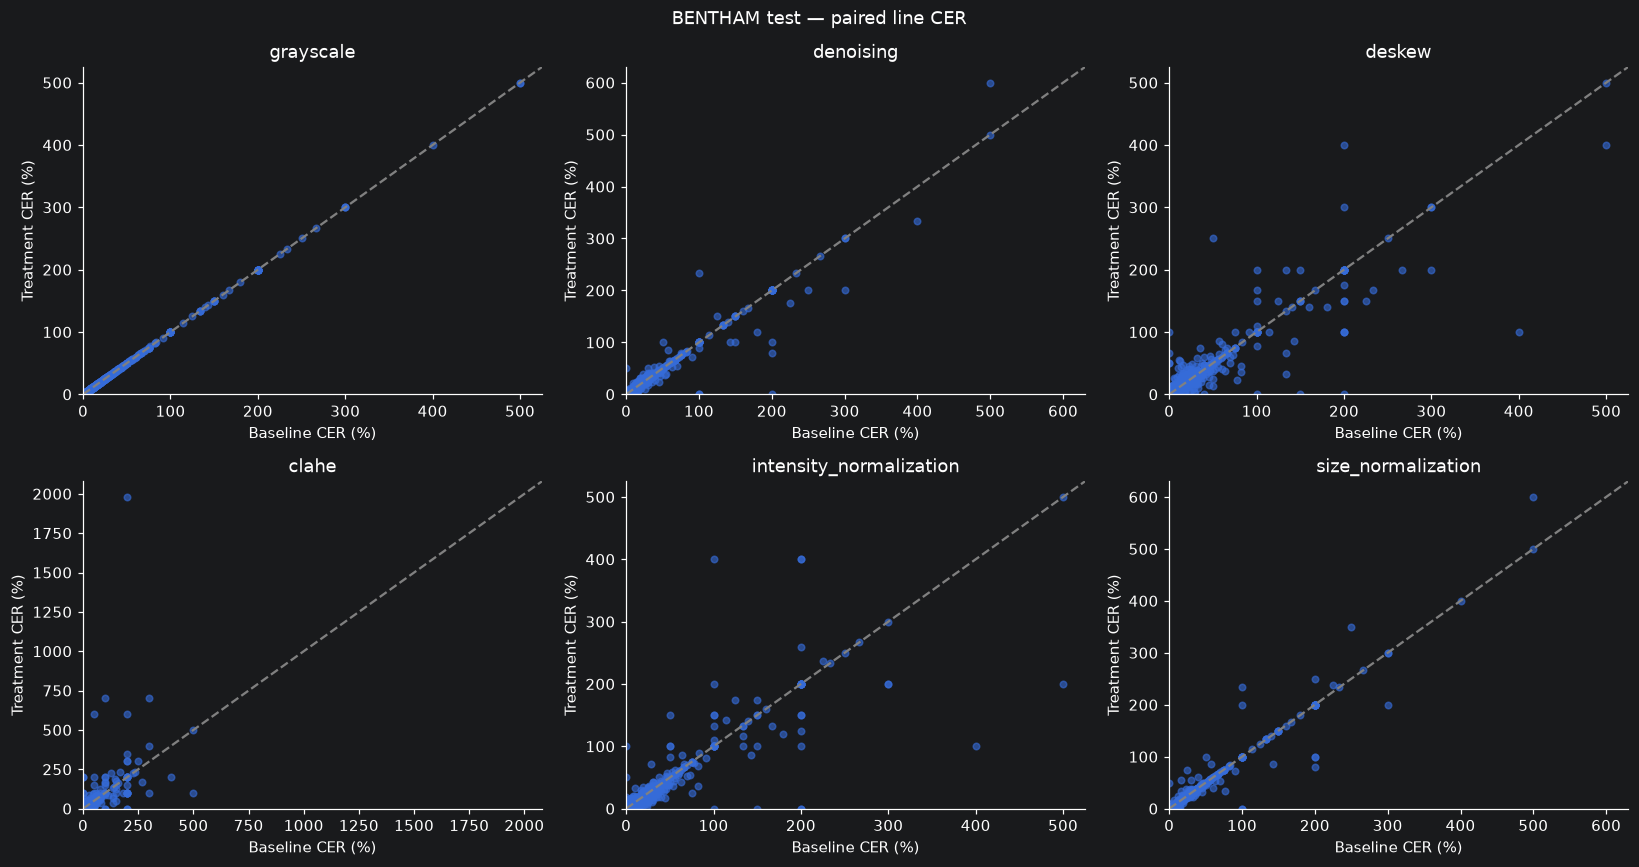

,dataset,configuration,Improved,Unchanged,Worsened
0,iam,grayscale,0,1000,0
1,iam,denoising,72,874,54
2,iam,deskew,63,869,68
3,iam,clahe,50,865,85
4,iam,intensity_normalization,32,939,29
5,iam,size_normalization,0,1000,0
6,bentham,grayscale,0,860,0
7,bentham,denoising,80,693,87
8,bentham,deskew,179,472,209
9,bentham,clahe,303,385,172


In [8]:
treatments = [name for name in pipeline_names if name != "baseline"]
paired_by_dataset = {}
outcome_rows = []
for dataset_name in selected:
    paired = predictions[predictions.dataset == dataset_name].pivot(index="sample_id", columns="configuration", values="cer")
    paired_by_dataset[dataset_name] = paired
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, name in zip(axes.flat, treatments):
        x, y = 100 * paired["baseline"], 100 * paired[name]
        limit = max(float(x.max()), float(y.max()), 1) * 1.05
        ax.scatter(x, y, alpha=.6, s=18)
        ax.plot([0, limit], [0, limit], "--", color="gray")
        ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Baseline CER (%)", ylabel="Treatment CER (%)", title=name)
        delta = paired[name] - paired["baseline"]
        same = np.isclose(delta, 0, atol=1e-12, rtol=0)
        outcome_rows.append({"dataset": dataset_name, "configuration": name,
            "Improved": int(((delta < 0) & ~same).sum()), "Unchanged": int(same.sum()),
            "Worsened": int(((delta > 0) & ~same).sum())})
    fig.suptitle(f"{dataset_name.upper()} test — paired line CER")
    fig.tight_layout()
    fig.savefig(run_dir / f"{dataset_name}_paired_line_cer.png", bbox_inches="tight")
    plt.show()
outcomes = pd.DataFrame(outcome_rows)
outcomes.to_csv(run_dir / "line_outcomes.csv", index=False)
display(outcomes)

iam/grayscale/sample_0
Reference: assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Baseline: assuredness " Bella Bella Marie " ( Bishopsome ) a lively song that changes tempo midway
Treatment: assuredness " Bella Bella Marie " ( Bishopsome ) a lively song that changes tempo midway


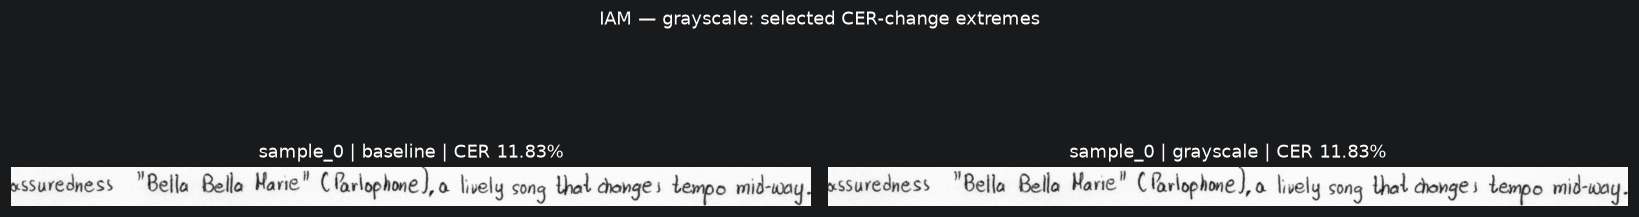

iam/denoising/sample_798
Reference: darkness .
Baseline: at a business .
Treatment: dazzeness .
iam/denoising/sample_1402
Reference: he was a keen member of the B.S.P. .
Baseline: he was a keen member of the B.S.P.
Treatment: he worn a beach in the winter of the Bo. I.P.


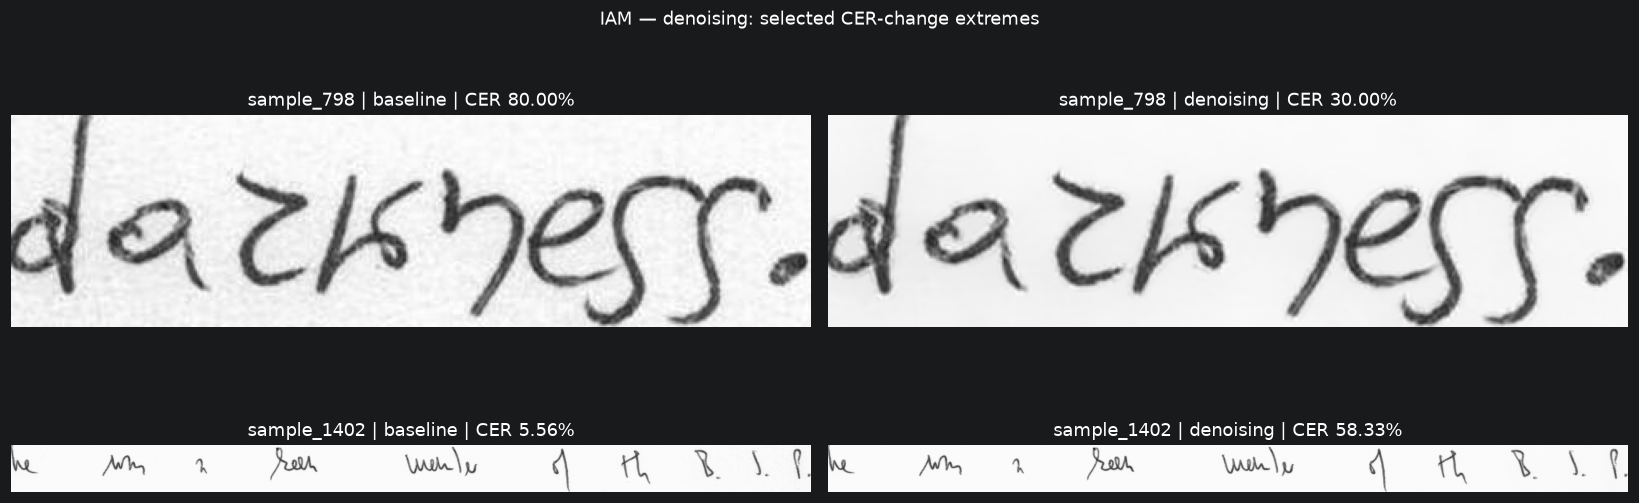

iam/deskew/sample_2817
Reference: you are satisfied . '
Baseline: you are saks " pedal .
Treatment: you are satisfied .
iam/deskew/sample_2868
Reference: I knew he was responsible for
Baseline: I knew he gives responsible for
Treatment: I knew he gave a new weapons at the four


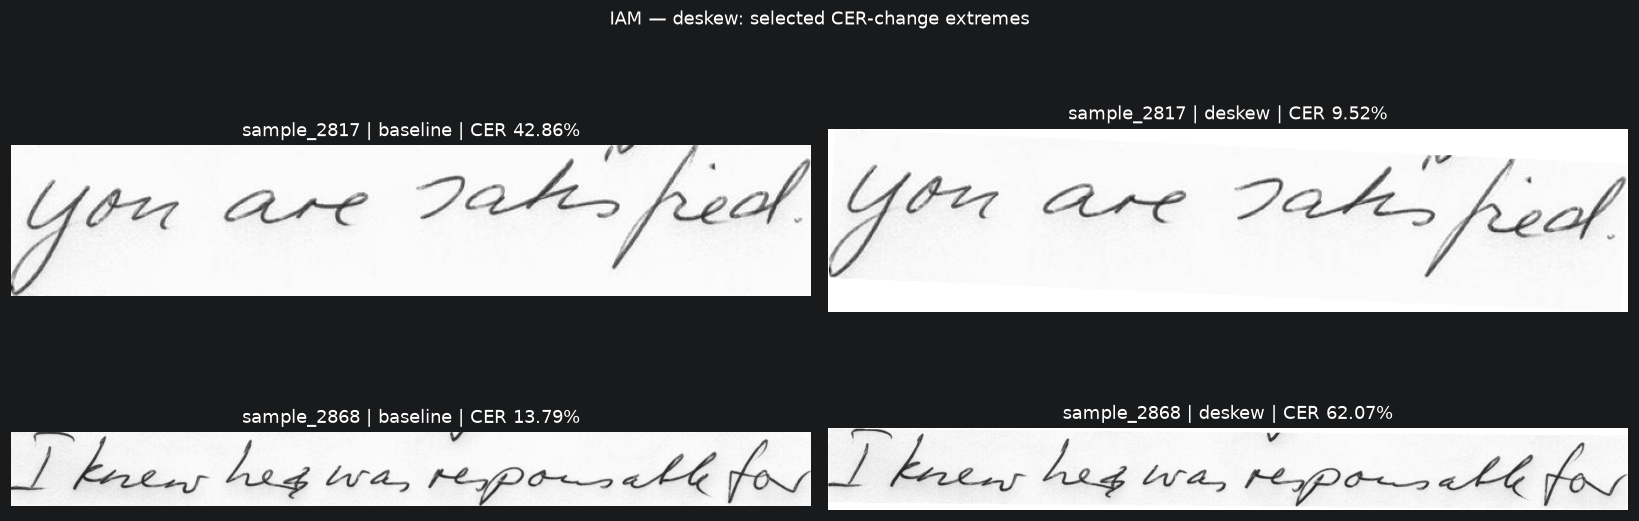

iam/clahe/sample_2836
Reference: ' I will leave you the necessary pre-
Baseline: I will leave you themselves every pre-
Treatment: I will leave you the necessary pre-
iam/clahe/sample_445
Reference: century .
Baseline: clinkerly .
Treatment: CLINKITY a


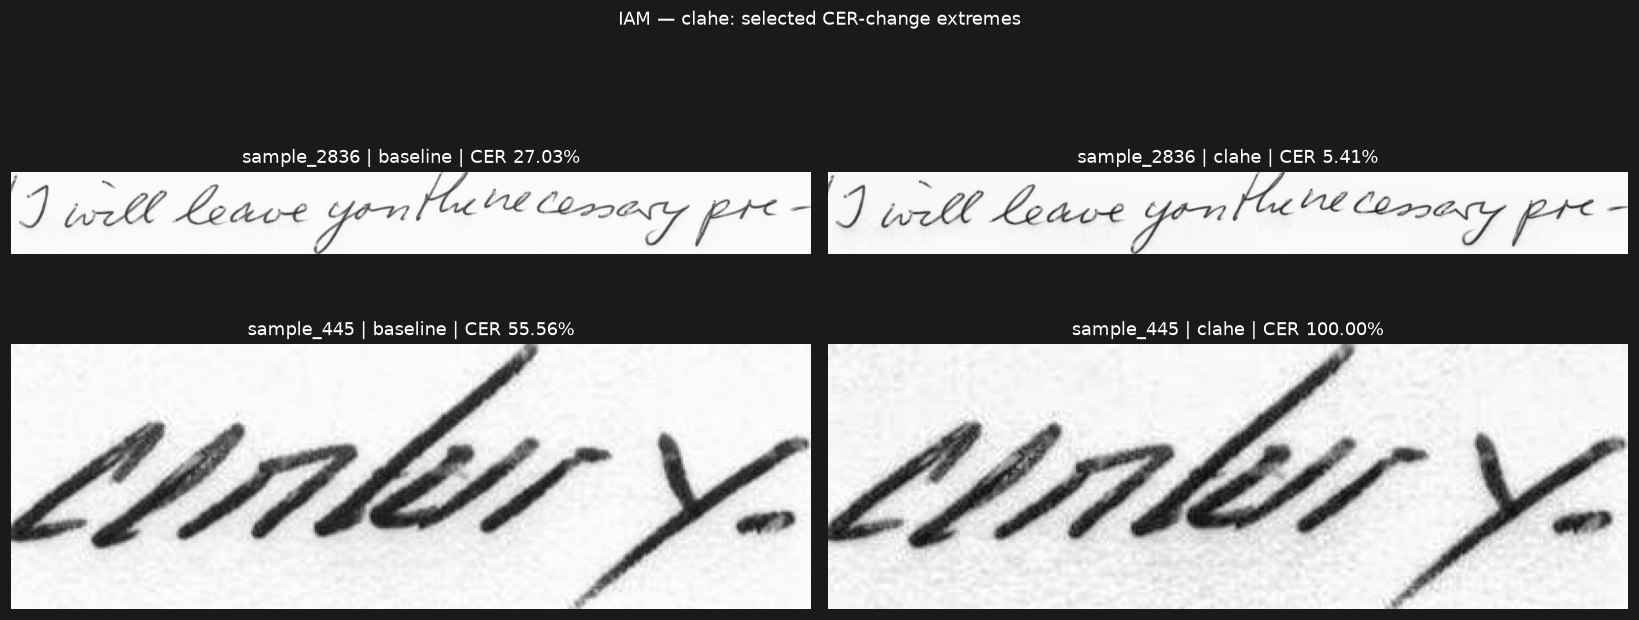

iam/intensity_normalization/sample_2161
Reference: put her interests before my own .
Baseline: put her interests before any ocean .
Treatment: put her interests before my own .
iam/intensity_normalization/sample_2744
Reference: suppose , to meet me for supper somewhere ? " she had
Baseline: furname , is met me for superior dimensions ? " She then
Treatment: Surname , is met at the RISE Summer Universiade ? " THE


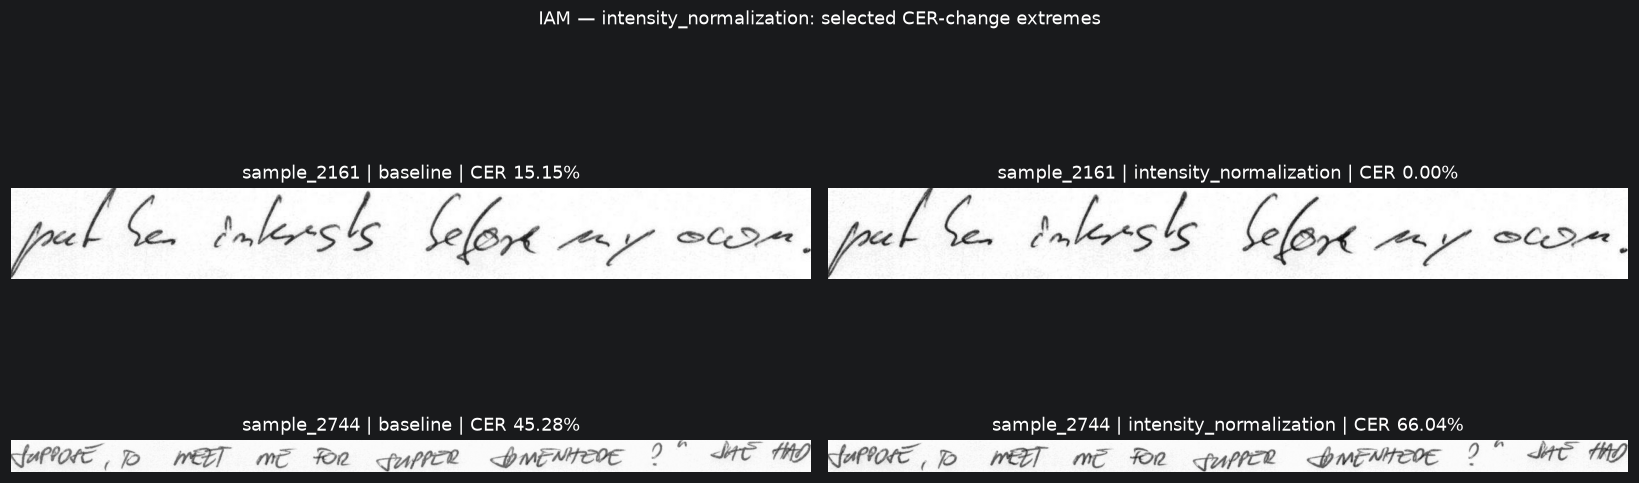

iam/size_normalization/sample_0
Reference: assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Baseline: assuredness " Bella Bella Marie " ( Bishopsome ) a lively song that changes tempo midway
Treatment: assuredness " Bella Bella Marie " ( Bishopsome ) a lively song that changes tempo midway


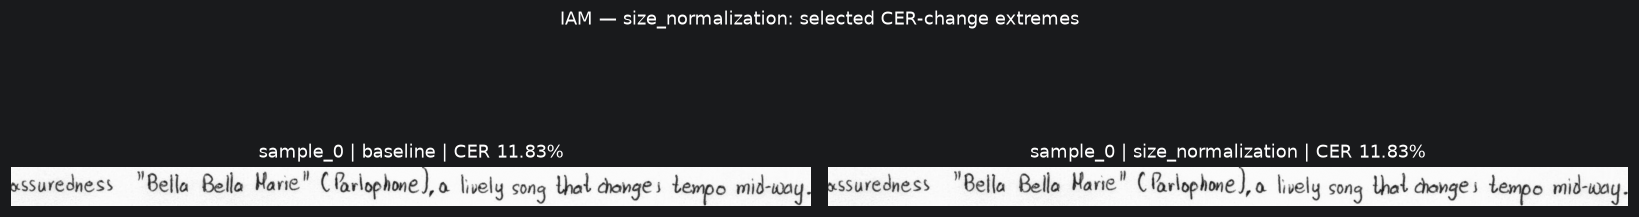

bentham/grayscale/002_579_001_01_01
Reference: 38 
Baseline: 358
Treatment: 358


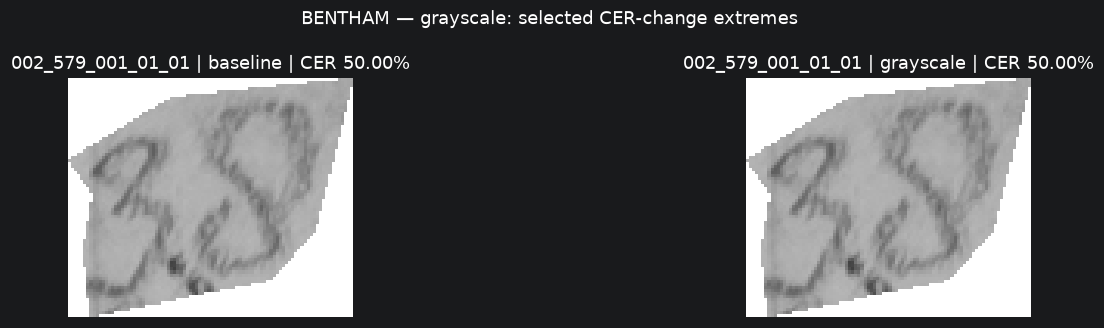

bentham/denoising/071_201_003_01_01
Reference: 3 
Baseline: a.
Treatment: 3
bentham/denoising/073_068_001_03_24
Reference: For 
Baseline: upon
Treatment: efforts .


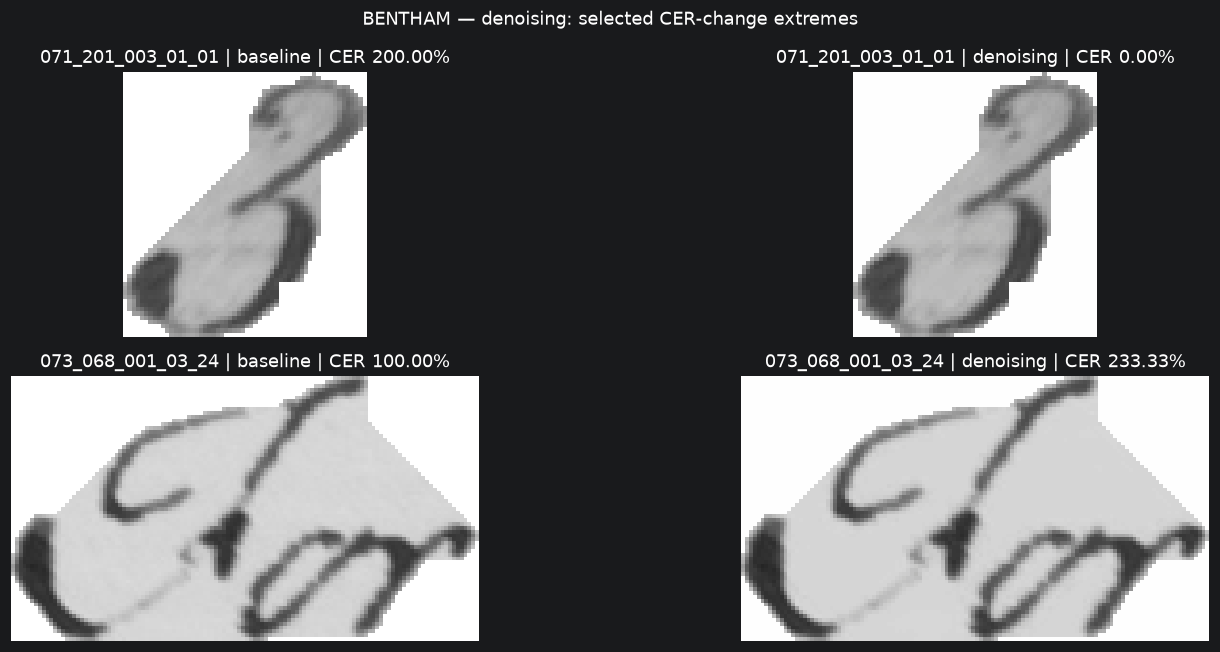

bentham/deskew/071_030_001_04_24
Reference: III 
Baseline: clack back .
Treatment: all
bentham/deskew/002_579_001_01_01
Reference: 38 
Baseline: 358
Treatment: crest


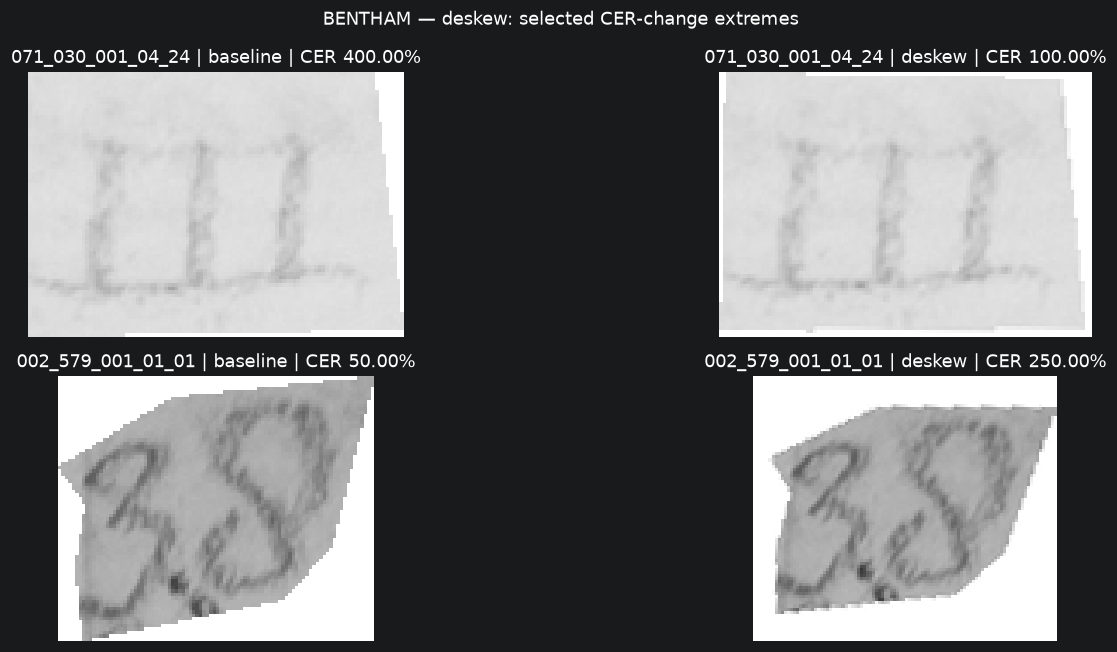

bentham/clahe/115_077_002_01_01
Reference: 9 
Baseline: ailey
Treatment: 0
bentham/clahe/072_049_002_04_05
Reference: or or 
Baseline: for the return
Treatment: " What you should be a member of the American Parliament of the American Parliament of the United States


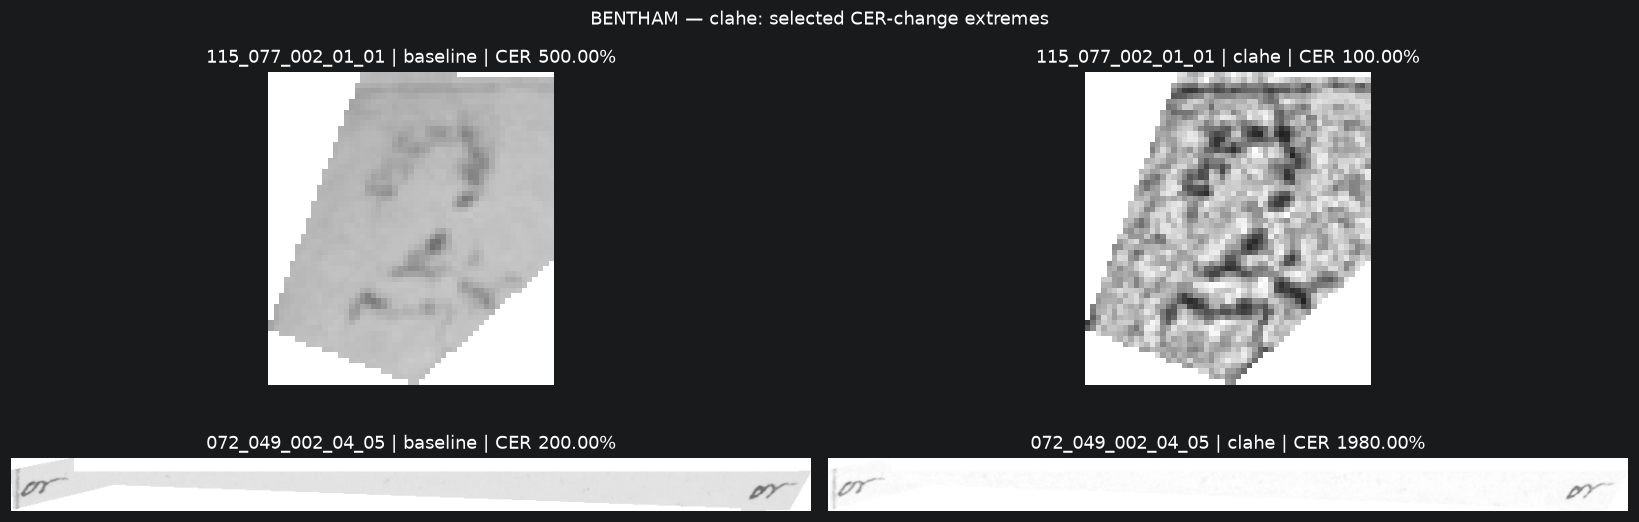

bentham/intensity_normalization/071_030_001_04_24
Reference: III 
Baseline: clack back .
Treatment: 111
bentham/intensity_normalization/071_030_001_04_13
Reference: 1 
Baseline: 2
Treatment: 6th.


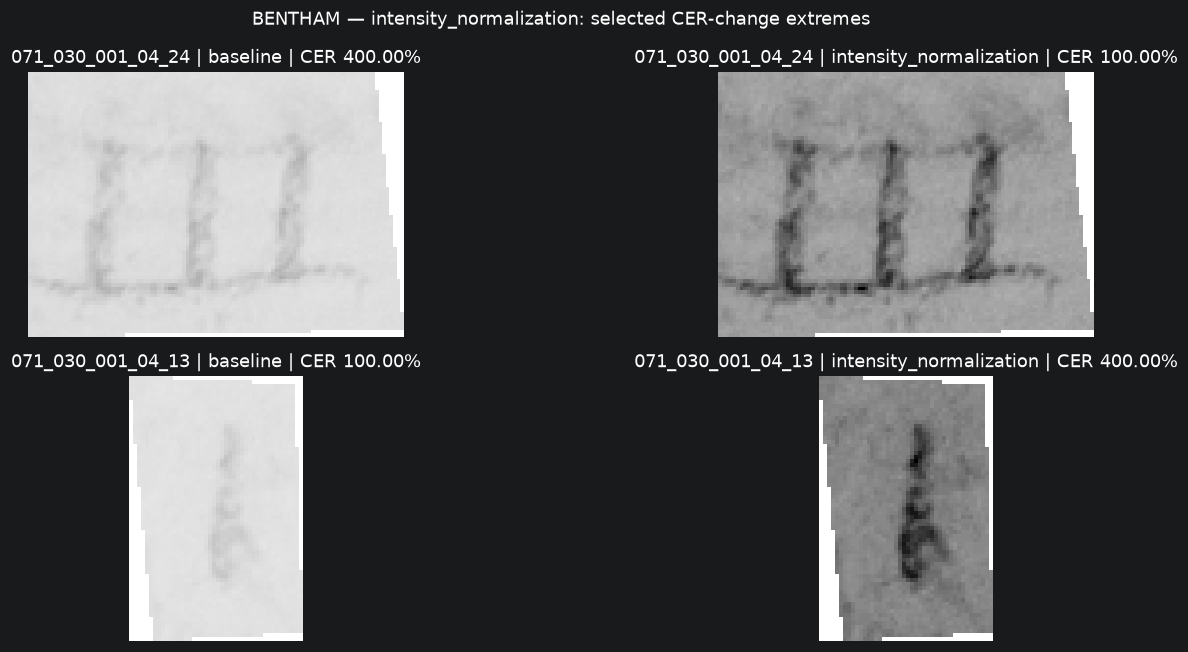

bentham/size_normalization/072_049_002_04_05
Reference: or or 
Baseline: for the return
Treatment: for the
bentham/size_normalization/073_068_001_03_24
Reference: For 
Baseline: upon
Treatment: efforts .


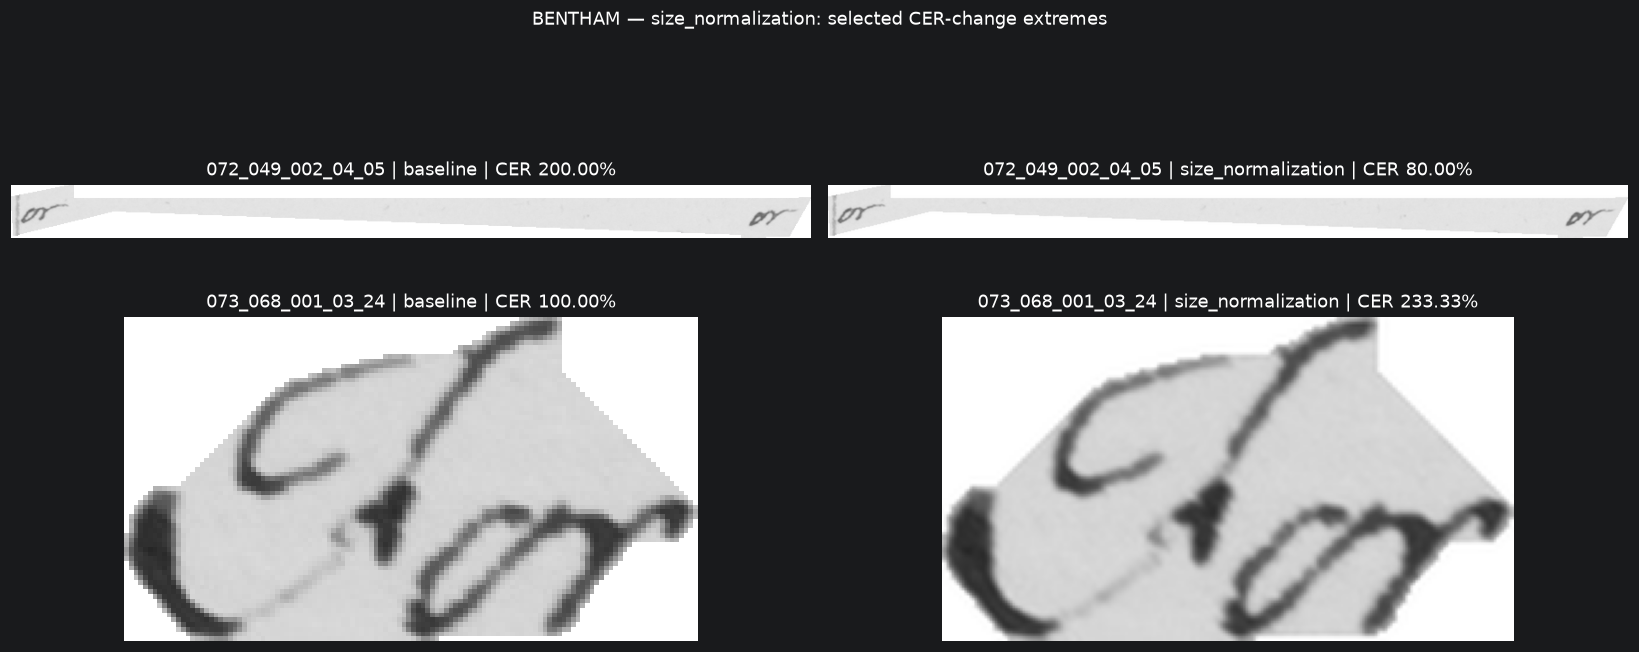

In [9]:
# Deliberately selected extremes for diagnosis, not representative examples.
for dataset_name in selected:
    paired = paired_by_dataset[dataset_name]
    sample_by_id = {s["id"]: s for s in samples_by_dataset[dataset_name]}
    lookup = predictions[predictions.dataset == dataset_name].set_index(["sample_id", "configuration"])
    for name in treatments:
        delta = paired[name] - paired["baseline"]
        example_ids = list(dict.fromkeys([delta.idxmin(), delta.idxmax()]))
        fig, axes = plt.subplots(len(example_ids), 2, figsize=(15, 3 * len(example_ids)), squeeze=False)
        for row, sample_id in enumerate(example_ids):
            sample = sample_by_id[sample_id]
            for col, config in enumerate(("baseline", name)):
                image = pipelines_by_dataset[dataset_name][config](sample["image"])
                axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=255)
                axes[row, col].set_title(f"{sample_id} | {config} | CER {100 * paired.loc[sample_id, config]:.2f}%")
                axes[row, col].axis("off")
            print(f"{dataset_name}/{name}/{sample_id}")
            print("Reference:", sample["ground_truth"])
            print("Baseline:", lookup.loc[(sample_id, "baseline"), "prediction"])
            print("Treatment:", lookup.loc[(sample_id, name), "prediction"])
        fig.suptitle(f"{dataset_name.upper()} — {name}: selected CER-change extremes")
        fig.tight_layout()
        fig.savefig(run_dir / f"{dataset_name}_examples_{name}.png", bbox_inches="tight")
        plt.show()

## Final results for IAM and Bentham

The tables below report corpus CER/WER and changes from the matching baseline for each dataset. Parameters were selected on validation and frozen before these test predictions. Treat the results as final measurements on the specified test samples (1000 IAM lines; all 860 Bentham test lines); no parameter tuning follows this evaluation.

Paired examples are diagnostic extremes, not evidence of statistical significance. IAM transcription conventions and the model's training-domain coverage affect interpretation. Deskew and optional resizing can alter the pixels seen by the mandatory model resize. Timings describe this machine and sequential run. A positive change means worse recognition; compare CER and WER separately when they disagree.

In [10]:
from src.evaluation.recognition import corpus_metrics
saved_metadata = json.loads((run_dir / "metadata.json").read_text())
assert saved_metadata["frozen_configuration_sha256"] == config_digest
assert len(predictions) == len(pipeline_names) * sum(sample_counts_by_dataset.values())
for (dataset_name, name), rows in predictions.groupby(["dataset", "configuration"], sort=False):
    assert len(rows) == sample_counts_by_dataset[dataset_name]
    measured = corpus_metrics(rows.ground_truth.tolist(), rows.prediction.tolist())
    recorded = summary[(summary.dataset == dataset_name) & (summary.configuration == name)].iloc[0]
    assert np.isclose(measured["cer"], recorded.cer, atol=1e-12, rtol=0)
    assert np.isclose(measured["wer"], recorded.wer, atol=1e-12, rtol=0)
assert outcomes[["Improved", "Unchanged", "Worsened"]].sum(axis=1).eq(outcomes.dataset.map(sample_counts_by_dataset)).all()
print("Frozen dataset-specific configurations selected on validation:")
display(selection_table.pivot(index="technique", columns="dataset", values="validation_configuration"))
columns = ["configuration", "sample_count", "cer_pct", "wer_pct", "cer_change_pp", "wer_change_pp"]
final_results = summary.assign(cer_pct=100 * summary.cer, wer_pct=100 * summary.wer)
for dataset_name in ("iam", "bentham"):
    print(f"{dataset_name.upper()} — FINAL TEST RESULTS ({sample_counts_by_dataset[dataset_name]} lines)")
    display(final_results[final_results.dataset == dataset_name][columns].round(4))
both_datasets = final_results.pivot(index="configuration", columns="dataset",
    values=["cer_pct", "wer_pct"]).reindex(pipeline_names)
print("Both datasets — corpus error rates (%)")
display(both_datasets.round(4))
both_datasets.to_csv(run_dir / "final_results_both_datasets.csv")
(run_dir / "status.json").write_text(json.dumps({"status": "complete",
    "split": "test", "sample_counts_by_dataset": sample_counts_by_dataset, "completed_dataset_configuration_pairs": 14}, indent=2))
print("Results:", run_dir)

Frozen dataset-specific configurations selected on validation:


dataset,bentham,iam
technique,,
clahe,clahe_clip2_grid16x16,clahe_clip1_grid8x8
denoising,nlm_h1,nlm_h7
deskew,deskew_max10_step0.25,deskew_max5_step0.5
grayscale,grayscale,grayscale
intensity_normalization,intensity_normalization,intensity_normalization
size_normalization,size_height128,size_height128


IAM — FINAL TEST RESULTS (1000 lines)


,configuration,sample_count,cer_pct,wer_pct,cer_change_pp,wer_change_pp
0,baseline,1000,4.8709,11.9336,0.0000,0.0000
2,grayscale,1000,4.8709,11.9336,0.0000,0.0000
4,denoising,1000,4.8546,11.8551,-0.0163,-0.0785
6,deskew,1000,4.9035,12.0682,0.0326,0.1346
8,clahe,1000,5.0758,12.3598,0.2049,0.4262
10,intensity_normalization,1000,4.8593,11.9672,-0.0116,0.0336
12,size_normalization,1000,4.8709,11.9336,0.0000,0.0000


BENTHAM — FINAL TEST RESULTS (860 lines)


,configuration,sample_count,cer_pct,wer_pct,cer_change_pp,wer_change_pp
1,baseline,860,17.4054,44.1286,0.0000,0.0000
3,grayscale,860,17.4054,44.1286,0.0000,0.0000
5,denoising,860,17.4080,43.9133,0.0026,-0.2153
7,deskew,860,17.7616,44.7603,0.3562,0.6316
9,clahe,860,15.8222,42.2481,-1.5833,-1.8806
11,intensity_normalization,860,16.7737,43.7123,-0.6317,-0.4163
13,size_normalization,860,17.3300,44.0281,-0.0754,-0.1005


Both datasets — corpus error rates (%)


cer_pct          wer_pct         
dataset                  bentham     iam  bentham      iam
configuration                                             
baseline                 17.4054  4.8709  44.1286  11.9336
grayscale                17.4054  4.8709  44.1286  11.9336
denoising                17.4080  4.8546  43.9133  11.8551
deskew                   17.7616  4.9035  44.7603  12.0682
clahe                    15.8222  5.0758  42.2481  12.3598
intensity_normalization  16.7737  4.8593  43.7123  11.9672
size_normalization       17.3300  4.8709  44.0281  11.9336

Results: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/test/experiment_a/20261115T224937039751Z
